In [1]:
import json
import numpy as np
import pickle as pkl
from sklearn import metrics
from scipy.optimize import minimize_scalar
from matplotlib import pyplot as plt
from datasets import load_metric

<frozen importlib._bootstrap>:241: RuntimeWarning: pyarrow.lib.Tensor size changed, may indicate binary incompatibility. Expected 64 from C header, got 80 from PyObject


In [ ]:
adjusted_metrics_bert_file = "results_adjusted_metrics_bert.json"
adjusted_metrics_bow_node2vec_gbdt_concat_file = "results_adjusted_metrics_bow_node2vec_gbdt_concat.json"
adjusted_metrics_ensemble_text_node2vec_gbdt_file = "results_adjusted_metrics_ensemble_text_node2vec_gbdt.json"
adjusted_metrics_gbdt_file = "results_adjusted_metrics_gbdt.json"
adjusted_metrics_gnn_bert_file = "results_adjusted_metrics_gnn_bert.json"
adjusted_metrics_linear_classifiers_file = "results_adjusted_metrics_linear_classifiers.json"
adjusted_metrics_node2vec_gbdt_file = "results_adjusted_metrics_node2vec_gbdt.json"

In [ ]:
adjusted_metrics_files = [
#     adjusted_metrics_linear_classifiers_file,
    adjusted_metrics_bow_node2vec_gbdt_concat_file,
#     adjusted_metrics_ensemble_text_node2vec_gbdt_file,
#     adjusted_metrics_gbdt_file,
#     adjusted_metrics_gnn_bert_file,
    # adjusted_metrics_bert_file,
#     adjusted_metrics_node2vec_gbdt_file
]

In [5]:
metric_acc = load_metric("accuracy")
metric_p = load_metric("precision")
metric_r = load_metric("recall")
metric_f = load_metric("f1")

NameError: name 'load_metric' is not defined

In [6]:
def predict(df, db=0):
    return [int(x>=db) for x in df ]

In [6]:
neg_pos_ratio_dict = {
    "is_rct": 5585042/489295,
    "is_sr": 5659292/121063,
    "is_casecontrol": 5628219/65790,
    "is_cohort": 5632460/78688,
    "is_guideline": 5676411/33826
}

def calc_precision(recall, specificity, neg_pos_ratio):
    return recall / (recall + neg_pos_ratio * (1 - specificity) + 1e-15)

def calc_f1(recall, precision):
    return 2*recall*precision/(recall+precision + 1e-15)

def get_scores(predictions):
    return [np.exp(p[1])/(np.exp(p[0]) + np.exp(p[1])) for p in predictions]

In [7]:
from transformers import TrainingArguments, Trainer
from transformers import AutoTokenizer
from transformers import AutoModelForSequenceClassification
from utils import get_texts_for_ptype
neg_to_pos_ratio=1

model = AutoModelForSequenceClassification.from_pretrained('trained/is_rct_distilbert-base-uncased')

X_train, X_val, X_test, y_train, y_val, y_test = get_texts_for_ptype('is_rct', inputs="titles_abstracts", neg_to_pos_ratio=neg_to_pos_ratio)

19it [00:24,  1.34s/it]/home/k2141255/.local/lib/python3.8/site-packages/tqdm/std.py:1182: DtypeWarning: Columns (14) have mixed types. Specify dtype option on import or set low_memory=False.
  for obj in iterable:
51it [01:06,  1.32s/it]/home/k2141255/.local/lib/python3.8/site-packages/tqdm/std.py:1182: DtypeWarning: Columns (14) have mixed types. Specify dtype option on import or set low_memory=False.
  for obj in iterable:
86it [01:52,  1.31s/it]
57it [01:25,  1.50s/it]


In [8]:
tokenizer = AutoTokenizer.from_pretrained('distilbert-base-uncased')

def tokenize_function(examples):
    return tokenizer(examples['text'], padding="max_length", truncation=True, max_length=420)

In [9]:
import pandas as pd
import datasets
test = pd.DataFrame()
test['label'] = y_test
test['text'] = list(X_test)
test_dataset = datasets.Dataset.from_pandas(test.reset_index(drop=True))
dataset = datasets.dataset_dict.DatasetDict(
            {
#                 'train': train_dataset,
#                 'val': val_dataset,
                'test': test_dataset
            }
        )
tokenized_datasets = dataset.map(tokenize_function, batched=True)
test_dataset = tokenized_datasets['test'].map(tokenize_function, batched=True)
test_dataset = test_dataset.shuffle(seed=42)

Map:   0%|          | 0/8000 [00:00<?, ? examples/s]

Map:   0%|          | 0/8000 [00:00<?, ? examples/s]

In [10]:
encoded_input = tokenizer(list(X_test), return_tensors='pt', truncation=True, padding=True).to('cuda')
model = model.to("cuda")

In [11]:
from tqdm import tqdm
input_ids = encoded_input['input_ids']
attention_mask = encoded_input['attention_mask']
outputs = []
for ii, am in zip(tqdm(input_ids), attention_mask):
    output = model(
        **{
            'input_ids': ii,
            'attention_mask': am
        }
    )
    outputs.append(output[0].cpu().detach().numpy())

100%|████████████████████████████████████████| 8000/8000 [00:35<00:00, 224.49it/s]


In [12]:
y_pred = np.argmax(np.concatenate(outputs, axis=0), axis=1)

In [13]:
metrics.roc_auc_score(y_score=y_pred, y_true=y_test)

0.9353750000000001

In [7]:
names_to_capital = {
    "distilbert-base-uncased": "Distill-BERT",
    "bert-base-cased": "BERT",
    "allenai/scibert_scivocab_uncased": "SciBERT",
    "dmis-lab/biobert-base-cased-v1.2": "BioBERT",
    "microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext": "PubMedBERT"
}

In [8]:
for adjusted_metrics_file in adjusted_metrics_files:
    with open(adjusted_metrics_file, "rb") as f:
        adjusted_metrics = pkl.load(f)
    
    model_class = adjusted_metrics_file.split('metrics_')[1].split('.json')[0]
    new_metrics_file = "finalized_metrics_" + model_class + ".json"
    
    finalized_metrics = []
    
    for adjusted_metric in adjusted_metrics:
        results_file = {}
        ptype = adjusted_metric['ptype']
        
        if 'scores' in adjusted_metric:
            y_score = adjusted_metric["scores"]
        elif 'scores_test' in adjusted_metric:
            y_score = adjusted_metric["scores_test"]
        elif 'df' in adjusted_metric:
            y_score = adjusted_metric["df"]
        else:
            if "outputs" in adjusted_metric:
                predictions = adjusted_metric["outputs"].predictions
            else:
                predictions = adjusted_metric["out"]
            y_score = get_scores(predictions)
        
        if "y_test" in adjusted_metric:
            y_test = adjusted_metric["y_test"]
        else:
            y_test = adjusted_metric["labels_test"]
        fpr, tpr, thresholds = metrics.roc_curve(y_test, y_score)
        
#         plt.plot(fpr, tpr)
        
            
        if 'model_type' in adjusted_metric:
            model_type = adjusted_metric['model_type']
            if ptype == "is_casecontrol" and model_type == "microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext":
                break
        
            results_file["model_type"] = model_type
            
        finalized_metrics.append(results_file)
    with open(new_metrics_file, 'w') as f:
        json.dump(finalized_metrics, f)

In [9]:
len(y_score)

8000

In [10]:
y_test.shape

(8000,)

In [11]:
ind = 2

In [12]:
adjusted_metrics[ind]['outputs']

PredictionOutput(predictions=array([[-0.35907432, -0.35827318],
       [-0.35907426, -0.3582732 ],
       [-0.35907432, -0.35827318],
       ...,
       [-0.35907438, -0.35827324],
       [-0.35907438, -0.3582733 ],
       [-0.3590742 , -0.35827318]], dtype=float32), label_ids=array([1, 0, 0, ..., 1, 0, 1]), metrics={'test_loss': 0.6931473612785339, 'test_accuracy': 0.5, 'test_precision': 0.5, 'test_recall': 1.0, 'test_f1': 0.6666666666666666, 'test_runtime': 1284.026, 'test_samples_per_second': 6.23, 'test_steps_per_second': 0.779})

In [13]:
y_pred =  adjusted_metrics[ind]['outputs'].predictions.argmax(axis=1)
set(y_pred)

{1}

In [16]:
y_true = adjusted_metrics[ind]['y_test']
set(y_true)

{0, 1}

In [17]:
def compute_metrics(eval_pred):
    
    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=-1)
    
    acc = metric_acc.compute(predictions=predictions, references=labels)['accuracy']
    p = metric_p.compute(predictions=predictions, references=labels)['precision']
    r = metric_r.compute(predictions=predictions, references=labels)['recall']
    f = metric_f.compute(predictions=predictions, references=labels)['f1']
    
#     tune.report(f1 = f)

    return {'accuracy': acc, 'precision': p, 'recall': r, 'f1': f}

In [18]:
accuracy_test = metric_acc.compute(predictions=y_pred, references=y_true)['accuracy']
accuracy_test

0.5

In [19]:
metrics.accuracy_score(y_true=y_true, y_pred=y_pred)

0.5

In [20]:
model_type

'microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext'

In [21]:
ptype

'is_casecontrol'

In [38]:
adjusted_metrics_files

['results_adjusted_metrics_bert.json']

In [40]:
tpr

array([0.     , 0.     , 0.0015 , 0.00275, 0.00725, 0.0115 , 0.02375,
       0.0435 , 0.0565 , 0.0845 , 0.1105 , 0.163  , 0.227  , 0.2655 ,
       0.32825, 0.373  , 0.433  , 0.466  , 0.51825, 0.57   , 0.60475,
       0.655  , 0.674  , 0.71775, 0.75875, 0.7745 , 0.806  , 0.82425,
       0.8515 , 0.879  , 0.88875, 0.90675, 0.9135 , 0.929  , 0.94425,
       0.9525 , 0.964  , 0.97075, 0.97825, 0.98075, 0.98525, 0.98975,
       0.99075, 0.9945 , 0.995  , 0.997  , 0.998  , 0.999  , 1.     ,
       1.     , 1.     ])

In [41]:
fpr

array([0.0000e+00, 2.5000e-04, 5.0000e-04, 2.5000e-03, 7.0000e-03,
       1.1000e-02, 2.4250e-02, 4.6500e-02, 6.3500e-02, 9.3500e-02,
       1.1850e-01, 1.6850e-01, 2.3275e-01, 2.7100e-01, 3.3675e-01,
       3.7400e-01, 4.2725e-01, 4.5900e-01, 5.1650e-01, 5.7400e-01,
       6.1000e-01, 6.6425e-01, 6.8450e-01, 7.2550e-01, 7.6750e-01,
       7.8600e-01, 8.1700e-01, 8.3150e-01, 8.5575e-01, 8.7475e-01,
       8.8450e-01, 9.0850e-01, 9.1600e-01, 9.3200e-01, 9.4500e-01,
       9.5150e-01, 9.6175e-01, 9.6550e-01, 9.7225e-01, 9.7475e-01,
       9.8225e-01, 9.8725e-01, 9.8975e-01, 9.9200e-01, 9.9350e-01,
       9.9550e-01, 9.9775e-01, 9.9875e-01, 9.9925e-01, 9.9975e-01,
       1.0000e+00])

In [42]:
def predict(df, db=0):
    return [int(x>=db) for x in df ]

In [44]:
bound_custom = 0.4435164
y_pred_test = predict(y_score, bound_custom)
recall_test_sub = metrics.recall_score(y_test, y_pred_test, pos_label=1)
recall_test_sub

1.0

In [45]:
spec_test = metrics.recall_score(y_test, y_pred_test, pos_label=0)
spec_test

0.0

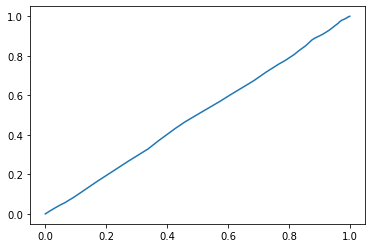

In [48]:
plt.plot(fpr, tpr)